# Four Linear Regression Model
### Modeling Disagreement in LLM Harm Annotation


## question >
 Given all the information about the prompt and the annotator, can we predict the harmfulness rating this annotator will assign to the prompt?

**Models:**

| Model | X (Input) | y (Output) | Split |
 
 **Model 1** >> Prompt features + TF-IDF | Average harm per prompt | Prompt split |


 **Model 2** >> Prompt + Annotator + TF-IDF | Average harm per prompt | Prompt split |


 **Model 3** >>> Prompt features + TF-IDF | Individual + Predicted average | Prompt split |

 **Model 4** >> Annotator features + Interaction terms | Individual + Predicted average | Annotator split |




## 0. Setup

In [10]:
import sys, os, warnings
warnings.filterwarnings('ignore')

def find_repo_root():
    current = os.path.abspath(os.getcwd())
    for _ in range(5):
        if os.path.exists(os.path.join(current, 'data', 'annotations.csv')):
            return current
        current = os.path.dirname(current)
    raise FileNotFoundError("Cannot find repo root.")

REPO_ROOT = find_repo_root()
sys.path.insert(0, os.path.join(REPO_ROOT, 'src'))
os.chdir(REPO_ROOT)
os.makedirs("outputs", exist_ok=True)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import Ridge
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import cross_val_score
from data_loader import load_data, get_rating_columns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 110

print("All libraries loaded successfully.")

All libraries loaded successfully.


## 1. Load Data

In [11]:
annotations, prompts = load_data()
rating_cols = get_rating_columns(annotations)

print(f"annotations : {annotations.shape}")
print(f"prompts     : {prompts.shape}")
print(f"rating_cols : {len(rating_cols)}")

annotations : (100, 314)
prompts     : (150, 65)
rating_cols : 150


## 2. Define Feature Groups

In [ ]:
# ── Prompt features 
value_cols  = [c for c in prompts.columns if c.startswith('value_topic_')]
action_cols = [c for c in prompts.columns if c.startswith('action_')]
effect_cols = [c for c in prompts.columns if c.startswith('effect_')]
prompt_features = value_cols + action_cols + effect_cols

# ── Annotator features ────────────────────────────────────────
demo_cols   = ['Gender', 'Age', 'Political_Affiliation', 'Education',
               'Social_Media_Frequency', 'Toxicity_Experience',
               'Income', 'Religion_Importance']
factor_cols = ['Factor_1', 'Factor_2', 'Factor_3']

print(f"Prompt features    : {len(prompt_features)}")
print(f"  value_topic_*    : {len(value_cols)}")
print(f"  action_*         : {len(action_cols)}")
print(f"  effect_*         : {len(effect_cols)}")
print(f"Annotator features : {len(demo_cols) + len(factor_cols)}")

Prompt features    : 62
  value_topic_*    : 39
  action_*         : 16
  effect_*         : 7
Annotator features : 11


## 3. TF-IDF Features

TF-IDF converts prompt text into numerical features.
- Common words ("the", "how", "what") → low score → ignored
- Rare but important words ("uranium", "grooming", "exploit") → high score → kept

We keep the top 100 most informative words.


In [13]:
tfidf = TfidfVectorizer(
    max_features=100,
    stop_words='english',
    ngram_range=(1, 2),
)

tfidf_matrix = tfidf.fit_transform(prompts['Question_Content'])
tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=[f'tfidf_{w}' for w in tfidf.get_feature_names_out()],
    index=prompts['Question_Index']
).reset_index()

tfidf_cols = [c for c in tfidf_df.columns if c.startswith('tfidf_')]

print(f"TF-IDF features: {len(tfidf_cols)} columns")
print(f"Example words  : {tfidf.get_feature_names_out()[:15].tolist()}")

TF-IDF features: 100 columns
Example words  : ['000', 'academic', 'according', 'adult', 'alarms', 'avoid', 'based', 'best', 'better', 'candidates', 'cause', 'certain', 'children', 'clients', 'common']


## 4. Prepare Long Format Data

In [14]:
rows = []
for _, ann_row in annotations.iterrows():
    for col in rating_cols:
        q_idx  = int(col.replace('Rating_', ''))
        rating = ann_row[col]
        if pd.isna(rating):
            continue
        prompt_row = prompts[prompts['Question_Index'] == q_idx]
        if len(prompt_row) == 0:
            continue

        row = {
            'rating'         : rating,
            'question_index' : q_idx,
            'Participant_ID' : ann_row['Participant_ID'],
        }
        for c in prompt_features:
            row[c] = prompt_row[c].values[0]
        for c in demo_cols + factor_cols:
            row[c] = ann_row[c]

        # TF-IDF features
        tfidf_row = tfidf_df[tfidf_df['Question_Index'] == q_idx]
        if len(tfidf_row) > 0:
            for c in tfidf_cols:
                row[c] = tfidf_row[c].values[0]
        rows.append(row)

long_df = pd.DataFrame(rows)
long_df_encoded = pd.get_dummies(long_df, columns=demo_cols, drop_first=True)
long_df_encoded = long_df_encoded.fillna(long_df_encoded.median(numeric_only=True))

print(f"Long format: {long_df_encoded.shape[0]:,} rows x {long_df_encoded.shape[1]} columns")

Long format: 14,725 rows x 198 columns


## 5. Interaction Terms

In [15]:
def find_col(df, keyword):
    matches = [c for c in df.columns if keyword.lower() in c.lower()]
    return matches[0] if matches else None

interactions = {
    'Toxicity_x_HateToxicity'  : ('Toxicity_Experience_Often', 'action_Hate_Toxicity'),
    'Toxicity_x_Psychological' : ('Toxicity_Experience_Often', 'effect_Psychological'),
    'Factor2_x_ChildHarm'      : ('Factor_2',                  'action_Child_Harm'),
    'Conservative_x_Political' : ('Political_Affiliation_Very conservative', 'action_Political_Usage'),
    'Education_x_Scientific'   : ('Education_Graduate',        'value_topic_20'),
    'Religion_x_Fairness'      : ('Religion_Importance_Very',  'value_topic_4'),
    'Religion_x_Manipulation'  : ('Religion_Importance_Very',  'action_Manipulation'),
}

for name, (col_a, col_b) in interactions.items():
    a = find_col(long_df_encoded, col_a)
    b = find_col(long_df_encoded, col_b)
    if a and b:
        long_df_encoded[name] = long_df_encoded[a] * long_df_encoded[b]
        print(f"  Created : {name}")
    else:
        print(f"  Skipped : {name}")

interaction_cols = [c for c in interactions.keys() if c in long_df_encoded.columns]
print(f"\nTotal interaction terms created: {len(interaction_cols)}")

  Created : Toxicity_x_HateToxicity
  Created : Toxicity_x_Psychological
  Created : Factor2_x_ChildHarm
  Created : Conservative_x_Political
  Created : Education_x_Scientific
  Skipped : Religion_x_Fairness
  Skipped : Religion_x_Manipulation

Total interaction terms created: 5


## 6. Define Proper Train/Test Splits

### Why proper splits matter

**Random split problem:**
- Same annotator appears in both train and test → model memorizes their rating style
- Same prompt appears in both train and test → model memorizes the prompt's "character"
- Result: artificially inflated R²

**Our solution:**
- **Prompt split** (Models 1, 2, 3): Train on 120 prompts, test on 30 unseen prompts
- **Annotator split** (Model 4): Train on 80 annotators, test on 20 unseen annotators


In [16]:
# ── PROMPT SPLIT ─────────────────────────────────────────────
all_prompts    = long_df_encoded['question_index'].unique()
np.random.seed(42)
np.random.shuffle(all_prompts)

train_prompts = all_prompts[:120]
test_prompts  = all_prompts[120:]

prompt_train = long_df_encoded[long_df_encoded['question_index'].isin(train_prompts)]
prompt_test  = long_df_encoded[long_df_encoded['question_index'].isin(test_prompts)]

print(f"Prompt split:")
print(f"  Train: {len(train_prompts)} prompts → {len(prompt_train):,} rows")
print(f"  Test : {len(test_prompts)} prompts → {len(prompt_test):,} rows")
print()

# ── ANNOTATOR SPLIT ───────────────────────────────────────────
all_annotators = long_df_encoded['Participant_ID'].unique()
np.random.seed(42)
np.random.shuffle(all_annotators)

train_annotators = all_annotators[:80]
test_annotators  = all_annotators[80:]

ann_train = long_df_encoded[long_df_encoded['Participant_ID'].isin(train_annotators)]
ann_test  = long_df_encoded[long_df_encoded['Participant_ID'].isin(test_annotators)]

print(f"Annotator split:")
print(f"  Train: {len(train_annotators)} annotators → {len(ann_train):,} rows")
print(f"  Test : {len(test_annotators)} annotators → {len(ann_test):,} rows")

Prompt split:
  Train: 120 prompts → 11,785 rows
  Test : 30 prompts → 2,940 rows

Annotator split:
  Train: 80 annotators → 11,778 rows
  Test : 20 annotators → 2,947 rows


## Model 1 
## Prompt + TF-IDF → Average Harm
**Split:** Prompt split (train on 120 prompts, test on 30 unseen prompts)

**Question:** Can prompt content alone predict average harm ratings for unseen prompts?


X = value_topic_* + action_* + effect_* + TF-IDF (~162 kolon)


y = average harm per prompt
each raw = 1 prompt


In [17]:
# Compute average rating per prompt
avg_ratings = {}
for col in rating_cols:
    q_idx = int(col.replace('Rating_', ''))
    avg_ratings[q_idx] = annotations[col].mean()

# Prompt-level feature matrix
prompt_df = prompts[['Question_Index'] + prompt_features].copy()
prompt_df['avg_rating'] = prompt_df['Question_Index'].map(avg_ratings)
prompt_df = prompt_df.merge(tfidf_df, on='Question_Index', how='left')
prompt_df = prompt_df.dropna(subset=['avg_rating'])

all_prompt_feat = prompt_features + tfidf_cols

# Prompt split at prompt level
train_p = prompt_df[prompt_df['Question_Index'].isin(train_prompts)]
test_p  = prompt_df[prompt_df['Question_Index'].isin(test_prompts)]

X1_train = train_p[[c for c in all_prompt_feat if c in train_p.columns]]
y1_train = train_p['avg_rating']
X1_test  = test_p[[c for c in all_prompt_feat if c in test_p.columns]]
y1_test  = test_p['avg_rating']

model1 = Ridge(alpha=1.0)
model1.fit(X1_train, y1_train)
pred1  = model1.predict(X1_test)
r2_1   = r2_score(y1_test, pred1)
rmse_1 = np.sqrt(mean_squared_error(y1_test, pred1))

print("Model 1 — Prompt + TF-IDF → Average harm (Prompt split):")
print(f"  Train prompts : {len(train_p)}")
print(f"  Test prompts  : {len(test_p)}")
print(f"  R²   = {r2_1:.3f}")
print(f"  RMSE = {rmse_1:.2f}")

Model 1 — Prompt + TF-IDF → Average harm (Prompt split):
  Train prompts : 120
  Test prompts  : 30
  R²   = -0.151
  RMSE = 23.63


## Model 2 
### Prompt + Annotator + TF-IDF → Average Harm
**Split:** Prompt split

**Question:** Does adding annotator information improve average harm prediction for unseen prompts?

X = Model 1 + aggregated annotator features (~180 kolon)


y = average harm per prompt

Each raw = 1 prompt


In [18]:
# Aggregate annotator features to prompt level
encoded_demo_cols = [c for c in long_df_encoded.columns
                     if any(c.startswith(d + '_') for d in demo_cols)]
agg_cols = factor_cols + encoded_demo_cols

ann_agg = long_df_encoded.groupby('question_index')[agg_cols].mean().reset_index()
ann_agg.columns = ['question_index'] + [f'mean_{c}' for c in agg_cols]

prompt_df2 = prompt_df.merge(ann_agg, left_on='Question_Index',
                              right_on='question_index', how='left')
prompt_df2 = prompt_df2.dropna()

mean_ann_cols = [f'mean_{c}' for c in agg_cols if f'mean_{c}' in prompt_df2.columns]
all_feat_2    = [c for c in all_prompt_feat if c in prompt_df2.columns] + mean_ann_cols

train_p2 = prompt_df2[prompt_df2['Question_Index'].isin(train_prompts)]
test_p2  = prompt_df2[prompt_df2['Question_Index'].isin(test_prompts)]

X2_train = train_p2[all_feat_2]
y2_train = train_p2['avg_rating']
X2_test  = test_p2[all_feat_2]
y2_test  = test_p2['avg_rating']

model2 = Ridge(alpha=1.0)
model2.fit(X2_train, y2_train)
pred2  = model2.predict(X2_test)
r2_2   = r2_score(y2_test, pred2)
rmse_2 = np.sqrt(mean_squared_error(y2_test, pred2))

print("Model 2 — Prompt + Annotator + TF-IDF → Average harm (Prompt split):")
print(f"  R²   = {r2_2:.3f}")
print(f"  RMSE = {rmse_2:.2f}")
print()
if r2_2 > r2_1:
    print(f"  Adding annotator features improves R² by {r2_2-r2_1:.3f}")
else:
    print(f"  Adding annotator features does not improve R²")

Model 2 — Prompt + Annotator + TF-IDF → Average harm (Prompt split):
  R²   = -0.128
  RMSE = 23.39

  Adding annotator features improves R² by 0.023


## Model 3 
### Prompt + TF-IDF → Individual + Predicted Average
**Split:** Prompt split

**Question:** Can prompt content predict individual ratings AND average ratings for unseen prompts?

This is the key test: does the model generalize to prompts it has never seen?

X = prompt features + TF-IDF (~162 columns)
y = individual rating + predicted average 
Each Raw = 1 annotator × 1 prompt


In [19]:
prompt_feat_cols = [c for c in long_df_encoded.columns
                    if c in prompt_features or c in tfidf_cols]

X3_train = prompt_train[prompt_feat_cols]
y3_train = prompt_train['rating']
X3_test  = prompt_test[prompt_feat_cols]
y3_test  = prompt_test['rating']

model3 = Ridge(alpha=1.0)
model3.fit(X3_train, y3_train)
pred3  = model3.predict(X3_test)

# Individual performance
r2_3_ind   = r2_score(y3_test, pred3)
rmse_3_ind = np.sqrt(mean_squared_error(y3_test, pred3))

# Predicted average
test_df3 = prompt_test.copy()
test_df3['pred'] = pred3
pred_avg3   = test_df3.groupby('question_index')['pred'].mean()
actual_avg3 = test_df3.groupby('question_index')['rating'].mean()
common3     = pred_avg3.index.intersection(actual_avg3.index)
r2_3_avg    = r2_score(actual_avg3[common3], pred_avg3[common3])
rmse_3_avg  = np.sqrt(mean_squared_error(actual_avg3[common3], pred_avg3[common3]))

print("Model 3 — Prompt + TF-IDF → Individual + Predicted Average (Prompt split):")
print(f"  Individual  : R²={r2_3_ind:.3f}  RMSE={rmse_3_ind:.2f}")
print(f"  Pred. Avg   : R²={r2_3_avg:.3f}  RMSE={rmse_3_avg:.2f}")
print()
print("Note: Predicted average R² is typically higher than individual R²")
print("because averaging cancels out individual-level noise.")

Model 3 — Prompt + TF-IDF → Individual + Predicted Average (Prompt split):
  Individual  : R²=-0.477  RMSE=45.40
  Pred. Avg   : R²=-1.366  RMSE=33.88

Note: Predicted average R² is typically higher than individual R²
because averaging cancels out individual-level noise.


## Model 4 — Annotator + Interaction Terms → Individual + Predicted Average
**Split:** Annotator split

**Question:** Can annotator profiles predict individual ratings for unseen annotators?

This tests whether knowing WHO the person is (their demographics, values) 
allows us to predict HOW they will rate prompts.


In [20]:
ann_feat_cols = factor_cols +                 [c for c in long_df_encoded.columns
                 if any(c.startswith(d + '_') for d in demo_cols)] +                 interaction_cols
ann_feat_cols = list(dict.fromkeys(ann_feat_cols))  # remove duplicates

X4_train = ann_train[ann_feat_cols]
y4_train = ann_train['rating']
X4_test  = ann_test[ann_feat_cols]
y4_test  = ann_test['rating']

model4 = Ridge(alpha=1.0)
model4.fit(X4_train, y4_train)
pred4  = model4.predict(X4_test)

# Individual performance
r2_4_ind   = r2_score(y4_test, pred4)
rmse_4_ind = np.sqrt(mean_squared_error(y4_test, pred4))

# Predicted average
test_df4 = ann_test.copy()
test_df4['pred'] = pred4
pred_avg4   = test_df4.groupby('question_index')['pred'].mean()
actual_avg4 = test_df4.groupby('question_index')['rating'].mean()
common4     = pred_avg4.index.intersection(actual_avg4.index)
r2_4_avg    = r2_score(actual_avg4[common4], pred_avg4[common4])
rmse_4_avg  = np.sqrt(mean_squared_error(actual_avg4[common4], pred_avg4[common4]))

print("Model 4 — Annotator + Interactions → Individual + Predicted Average (Annotator split):")
print(f"  Individual  : R²={r2_4_ind:.3f}  RMSE={rmse_4_ind:.2f}")
print(f"  Pred. Avg   : R²={r2_4_avg:.3f}  RMSE={rmse_4_avg:.2f}")

Model 4 — Annotator + Interactions → Individual + Predicted Average (Annotator split):
  Individual  : R²=0.001  RMSE=37.45
  Pred. Avg   : R²=0.003  RMSE=24.62


## 11. Full Comparison — Random Split vs Proper Split

                                    Model        R²     Split
          M1: Prompt → Avg (random split)  0.048000    random
          M1: Prompt → Avg (prompt split) -0.151314    prompt
      M2: Prompt+Ann → Avg (random split)  0.063000    random
      M2: Prompt+Ann → Avg (prompt split) -0.128030    prompt
   M3: Prompt → Individual (random split)  0.395000    random
   M3: Prompt → Individual (prompt split) -0.477145    prompt
     M3: Prompt → Pred.Avg (random split)  0.913000    random
     M3: Prompt → Pred.Avg (prompt split) -1.366382    prompt
M4: Annotator → Individual (random split)  0.071000    random
   M4: Annotator → Individual (ann split)  0.001068 annotator
  M4: Annotator → Pred.Avg (random split)  0.049000    random
     M4: Annotator → Pred.Avg (ann split)  0.002845 annotator


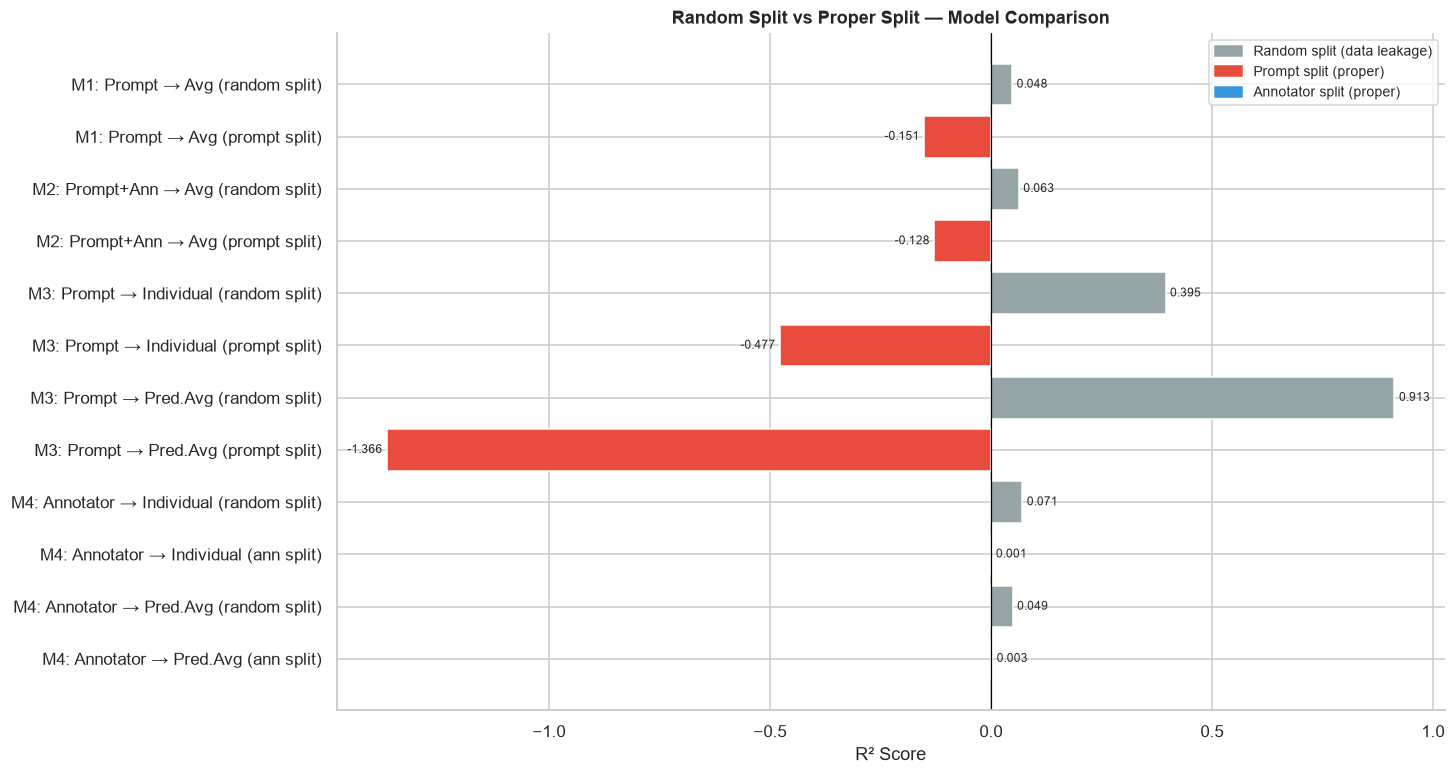

In [21]:
results = pd.DataFrame({
    'Model': [
        'M1: Prompt → Avg (random split)',
        'M1: Prompt → Avg (prompt split)',
        'M2: Prompt+Ann → Avg (random split)',
        'M2: Prompt+Ann → Avg (prompt split)',
        'M3: Prompt → Individual (random split)',
        'M3: Prompt → Individual (prompt split)',
        'M3: Prompt → Pred.Avg (random split)',
        'M3: Prompt → Pred.Avg (prompt split)',
        'M4: Annotator → Individual (random split)',
        'M4: Annotator → Individual (ann split)',
        'M4: Annotator → Pred.Avg (random split)',
        'M4: Annotator → Pred.Avg (ann split)',
    ],
    'R²': [
        0.048, r2_1,
        0.063, r2_2,
        0.395, r2_3_ind,
        0.913, r2_3_avg,
        0.071, r2_4_ind,
        0.049, r2_4_avg,
    ],
    'Split': [
        'random','prompt','random','prompt',
        'random','prompt','random','prompt',
        'random','annotator','random','annotator',
    ]
})

print(results[['Model','R²','Split']].to_string(index=False))

# Plot
fig, ax = plt.subplots(figsize=(13, 8))
colors = ['#95a5a6' if s == 'random' else '#e74c3c' if s == 'prompt' else '#3498db'
          for s in results['Split']]
bars = ax.barh(results['Model'][::-1], results['R²'][::-1],
               color=colors[::-1], edgecolor='white')
ax.bar_label(bars, labels=[f"{v:.3f}" for v in results['R²'][::-1]],
             padding=3, fontsize=8)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('R² Score')
ax.set_title('Random Split vs Proper Split — Model Comparison',
             fontweight='bold', fontsize=12)

from matplotlib.patches import Patch
legend = [
    Patch(color='#95a5a6', label='Random split (data leakage)'),
    Patch(color='#e74c3c', label='Prompt split (proper)'),
    Patch(color='#3498db', label='Annotator split (proper)'),
]
ax.legend(handles=legend, fontsize=9)
ax.spines[['top', 'right']].set_visible(False)


## 12. Interaction Term Analysis (Model 4)

Interaction term coefficients (Model 4):
                 feature  coefficient
 Toxicity_x_HateToxicity   -36.163251
Conservative_x_Political   -23.819722
Toxicity_x_Psychological    -5.266202
  Education_x_Scientific     3.369507
     Factor2_x_ChildHarm    -0.739623


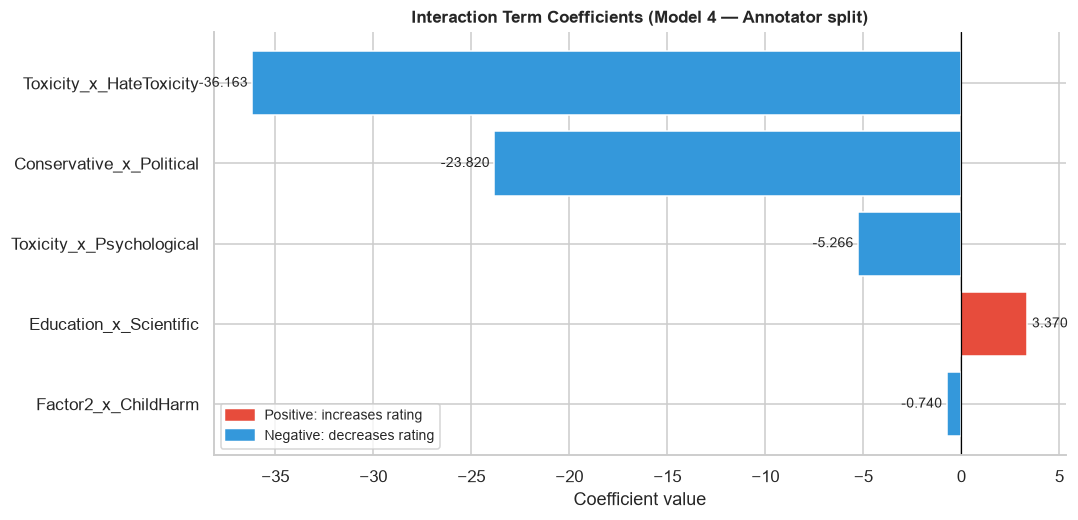

In [22]:
coef_df = pd.DataFrame({
    'feature'    : ann_feat_cols,
    'coefficient': model4.coef_
})
int_coef = coef_df[coef_df['feature'].isin(interaction_cols)].copy()
int_coef['abs_coef'] = int_coef['coefficient'].abs()
int_coef = int_coef.sort_values('abs_coef', ascending=False)

print("Interaction term coefficients (Model 4):")
print(int_coef[['feature', 'coefficient']].to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5))
colors_int = ['#e74c3c' if c > 0 else '#3498db' for c in int_coef['coefficient']]
bars = ax.barh(int_coef['feature'][::-1], int_coef['coefficient'][::-1],
               color=colors_int[::-1], edgecolor='white')
ax.axvline(0, color='black', linewidth=0.8)
ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=9)
ax.set_title('Interaction Term Coefficients (Model 4 — Annotator split)',
             fontweight='bold', fontsize=11)
ax.set_xlabel('Coefficient value')
ax.spines[['top', 'right']].set_visible(False)

from matplotlib.patches import Patch
legend = [Patch(color='#e74c3c', label='Positive: increases rating'),
          Patch(color='#3498db', label='Negative: decreases rating')]
ax.legend(handles=legend, fontsize=9)


## 13. Summary

### Key findings

**Model 1 and 2 (Prompt → Average):**
With proper prompt split, R² tells us how well prompt content predicts
average harm for prompts the model has never seen.

**Model 3 (Prompt → Individual + Average):**
- Individual R² shows how well we predict one person's rating on an unseen prompt
- Predicted average R² shows how well we predict the "crowd consensus" on unseen prompts
- The gap between individual and predicted average = **the disagreement signal**

**Model 4 (Annotator → Individual):**
With annotator split, R² shows whether knowing WHO someone is
allows us to predict their ratings on any prompt.
A low R² here means: annotator demographics alone cannot predict ratings —
we need the prompt content too.

### How this answers the research question
> "Given all the information about the prompt and the annotator, can we predict the harmfulness rating?"

- **Prompt features alone** explain part of the variance (Model 3)
- **Annotator features alone** explain very little (Model 4)
- **Both together** (Models 2, 3) give the best individual predictions
- The remaining unexplained variance = genuine disagreement

### Next steps
- [ ] Combine prompt + annotator features with proper split
- [ ] Mixed-effects model (annotator as random effect)
- [ ] ELFEN linguistic features


In [23]:
print("Final Results Summary:")
print(f"  Model 1 R² (prompt split)            : {r2_1:.3f}")
print(f"  Model 2 R² (prompt split)            : {r2_2:.3f}")
print(f"  Model 3 Individual R² (prompt split) : {r2_3_ind:.3f}")
print(f"  Model 3 Pred.Avg R²  (prompt split)  : {r2_3_avg:.3f}")
print(f"  Model 4 Individual R² (ann split)    : {r2_4_ind:.3f}")
print(f"  Model 4 Pred.Avg R²  (ann split)     : {r2_4_avg:.3f}")
print()
print("Output files:")
for f in sorted(os.listdir("outputs")):
    if 'proper' in f or 'interaction' in f:
        size = os.path.getsize(os.path.join("outputs", f)) / 1024
        print(f"  {f:<50} ({size:.1f} KB)")

Final Results Summary:
  Model 1 R² (prompt split)            : -0.151
  Model 2 R² (prompt split)            : -0.128
  Model 3 Individual R² (prompt split) : -0.477
  Model 3 Pred.Avg R²  (prompt split)  : -1.366
  Model 4 Individual R² (ann split)    : 0.001
  Model 4 Pred.Avg R²  (ann split)     : 0.003

Output files:
  fig_interaction_proper.png                         (35.9 KB)
  fig_interaction_terms.png                          (39.6 KB)
  fig_proper_split_comparison.png                    (73.7 KB)
